# Environmental Toxin Analysis in River Systems

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

In [10]:
df=pd.read_csv("C:/Users/yekta/OneDrive/Desktop/Datasets/National_River_Toxin_Dataset_1.csv")

In [5]:
df.head()

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1305 non-null   object 
 1   River_System      1305 non-null   object 
 2   pH_Level          1278 non-null   float64
 3   Temperature       1278 non-null   float64
 4   Lead              1285 non-null   float64
 5   Mercury           1278 non-null   float64
 6   Arsenic           1279 non-null   float64
 7   Nitrates          1265 non-null   float64
 8   Phosphates        1282 non-null   float64
 9   Dissolved_Oxygen  1284 non-null   float64
dtypes: float64(8), object(2)
memory usage: 102.1+ KB


In [7]:
df.describe()

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
count,1278.000000,1278.000000,1285.000000,1278.000000,1279.000000,1265.000000,1282.000000,1284.000000
mean,7.353247,20.041668,3.011035,0.596108,3.597916,10.038789,0.497162,8.023795
std,0.349114,4.063638,0.874431,0.175150,0.992052,2.096641,0.106304,1.064190
min,6.465087,9.891618,0.551349,0.157117,1.485608,2.025075,0.144044,5.041394
25%,7.101324,16.813976,2.366298,0.462683,2.836160,8.701188,0.422006,7.269386
50%,7.339326,20.039121,3.000714,0.599186,3.511678,10.089112,0.497631,8.007448
75%,7.585733,23.358634,3.676560,0.734863,4.298946,11.391686,0.572888,8.740828
max,8.392902,30.749449,5.800963,1.057494,6.232902,16.547073,0.870007,11.228677


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("C:/Users/yekta/OneDrive/Desktop/Datasets/National_River_Toxin_Dataset_1.csv")
df.shape[0]

1305

In [5]:
df.shape[1]

10

### Check for missing values

In [6]:
df.isnull().sum()

Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64

### Handle any missing or inconsistent data

In [7]:
df.dropna(inplace=True)

### fill missing values in numeric columns only

In [14]:
numeric_columns= df.select_dtypes(include=[np.number]).columns
df[numeric_columns]= df[numeric_columns].fillna(df[numeric_columns].mean())

### Convert data types

In [8]:
df["Date"]=pd.to_datetime(df["Date"])


### The avarage level of toxin

In [15]:
Avarage_toxins_level= df[["Lead", "Mercury", "Arsenic"]].mean()
print(f"Avarage toxins level: {Avarage_toxins_level}")

Avarage toxins level: Lead       3.011035
Mercury    0.596108
Arsenic    3.597916
dtype: float64


### Identify top pulluted rivers by avarage lead levels

In [19]:
top_pulluted_rivers= df.groupby("River_System")["Lead"].mean().sort_values(ascending=False)
print(f"Top pulluted rivers:{top_pulluted_rivers}")

Top pulluted rivers:River_System
Yangtze        4.011200
Mississippi    3.478198
Nile           2.990203
Danube         2.544912
Amazon         2.030662
Name: Lead, dtype: float64


### Bar chart for avarage lead levels per river

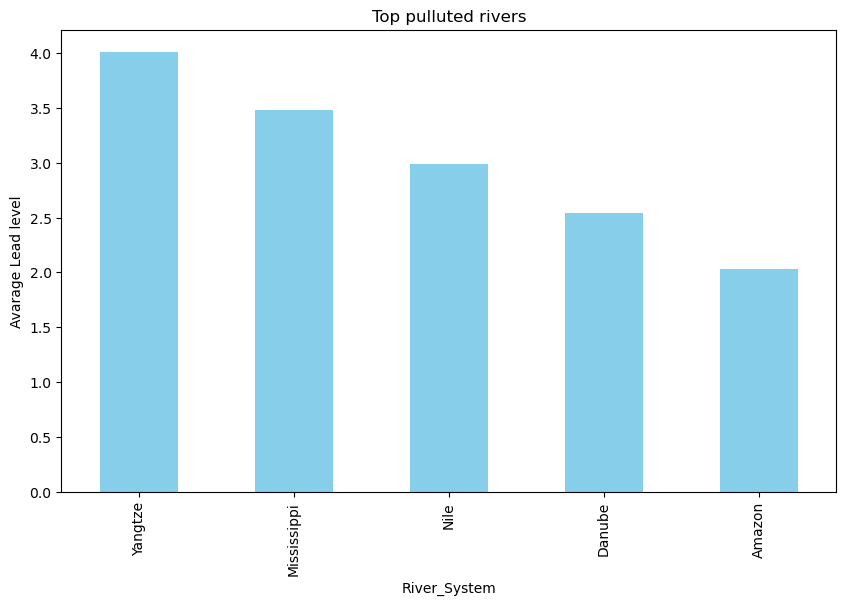

In [25]:
plt.figure(figsize=(10,6))
top_pulluted_rivers.plot(kind="bar", color= "skyblue")
plt.title("Top pulluted rivers")
plt.xlabel("River_System")
plt.ylabel("Avarage Lead level")
plt.show()

### Line graph for toxin levels overtime

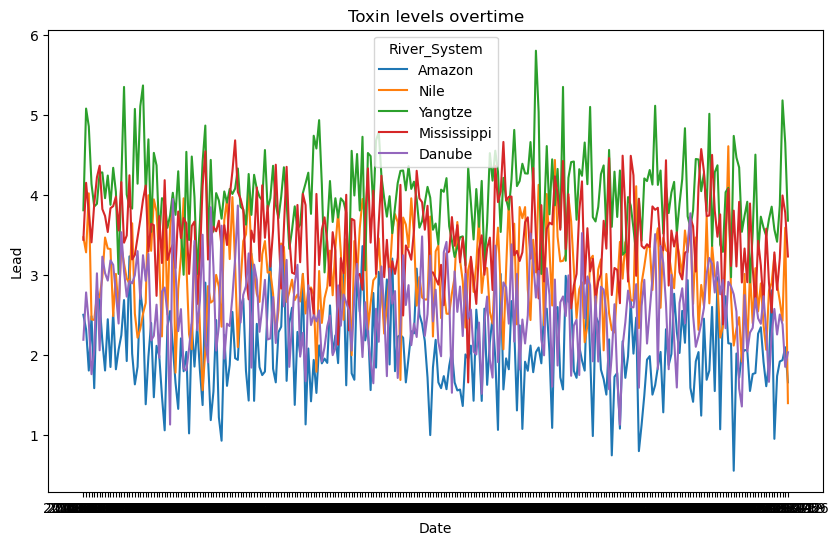

In [29]:
plt.figure(figsize=(10,6))
sns.lineplot(x="Date", y="Lead", data=df, hue="River_System", errorbar=None)
plt.title("Toxin levels overtime")
plt.xlabel("Date")
plt.ylabel("Lead")
plt.show()

### Correlation matrix

In [31]:
corrolation_matrix=df[numeric_columns].corr()
print(f"corrolation_matrix: {corrolation_matrix}")

corrolation_matrix:                   pH_Level  Temperature      Lead   Mercury   Arsenic  \
pH_Level          1.000000     0.167589  0.319700  0.137656  0.042514   
Temperature       0.167589     1.000000  0.124512  0.160928  0.044863   
Lead              0.319700     0.124512  1.000000  0.538168  0.566595   
Mercury           0.137656     0.160928  0.538168  1.000000  0.685925   
Arsenic           0.042514     0.044863  0.566595  0.685925  1.000000   
Nitrates          0.082121     0.246166  0.029522  0.062318  0.034924   
Phosphates        0.089348     0.314542 -0.000937  0.005734 -0.004483   
Dissolved_Oxygen -0.058682    -0.279058 -0.027448 -0.001926  0.020435   

                  Nitrates  Phosphates  Dissolved_Oxygen  
pH_Level          0.082121    0.089348         -0.058682  
Temperature       0.246166    0.314542         -0.279058  
Lead              0.029522   -0.000937         -0.027448  
Mercury           0.062318    0.005734         -0.001926  
Arsenic           0.034924 

### Heatmap for correlation between different parameters

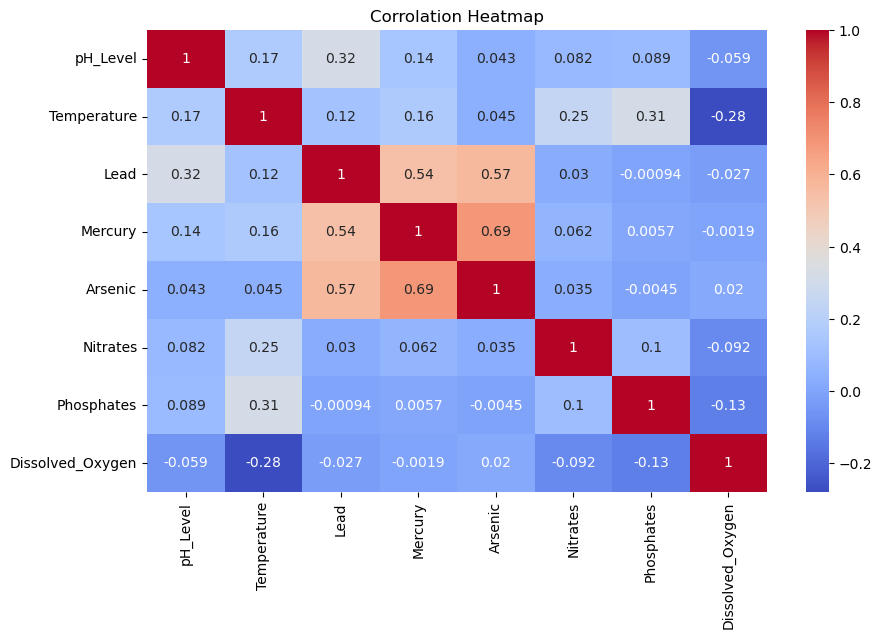

In [34]:
plt.figure(figsize=(10,6))
sns.heatmap(corrolation_matrix, annot= True, cmap="coolwarm")
plt.title("Corrolation Heatmap")
plt.show()

### T-test between two River System

In [42]:
Amazon_data=df[df["River_System"]== "Amazon"]["Lead"]
Nile_data=df[df["River_System"]=="Nile"]["Lead"]
t_test,p_value= stats.ttest_ind(Amazon_data, Nile_data)
print(f"T_test and p_value between Nile and Amazon, T_statistic: {t_test}, p_value{p_value}")


T_test and p_value between Nile and Amazon, T_statistic: -20.23821779031797, p_value1.3375120881428663e-67


### Linear regression between toxins and PH

In [48]:
x=df[["pH_Level"]]
y=df["Lead"]
model=LinearRegression()
model.fit(x,y)
print(f"Linear Regression Coefficients: {model.coef_}")
print(f"Linear Regression Intercept: {model.intercept_}")


Linear Regression Coefficients: [0.80294889]
Linear Regression Intercept: -2.89324669492776
